In [1]:
%pip install sqlalchemy

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 603.1 kB/s eta 0:00:04
   -------- ------------------------------- 0.5/2.4 MB 603.1 kB/s eta 0:00:04
   -------- ------------------------------- 0.5/2.4 MB 603.1 kB/s eta 0:00:04
   ------------ --------------------------- 0.8/2.4 MB 483.3 kB/s eta 0:00:04
   ------------ --------------------------- 0.8/2.4 MB 483.3 kB/s eta 0:00:04
   ------------ --------------------------- 0.8/2.4 MB 483.3 kB/s eta 0:00:04
   ------------ --------------------------- 0.8/2.4 MB 483.3 kB/s eta 0:00:04
   ------------ ------------------------


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import sqlalchemy

In [2]:
#engine = create_engine("mysql+mysqlconnector://root:System:@localhost:3306/Capstone")
from sqlalchemy import create_engine, URL

connection_url = URL.create(
    drivername="mysql+mysqlconnector",
    username="root",
    password="System",  # Replace with your actual MySQL password
    host="localhost",
    port=3306,
    database="Capstone"
)
engine = create_engine(connection_url)
with engine.connect() as connection:
    print("Connected database")
          #connection.execute(text("SELECT DATABASE()")).scalar())

Connected database


In [3]:
import pandas as pd

# TASK 1
# LOADING ORDERS ,ORDER ITEMS , CUSTOMERS TABLE

In [4]:
orders = pd.read_sql("select * from orders",engine)
orders.head(3)

,order_id,Customer_id,Order_status,Order_Status2,Order_date,Required_date,Shipped_date,Store_id,Staff_id
0,1,259,4,Delivered,2016-01-01,2016-01-03,2016-01-03,1,2
1,2,1212,4,Delivered,2016-01-01,2016-01-04,2016-01-03,2,6
2,3,523,4,Delivered,2016-01-02,2016-01-05,2016-01-03,2,7


In [5]:
# ORDER _ITEMS
order_items = pd.read_sql("select * from order_items",engine)
order_items.head(3)

,Order_ID,Item_ID,Product_ID,Product_Name,Quantity,List_Price,Discount,Total_Sales
0,1,1,20,Electra Townie Original 7D EQ - Women's - 2016,1,599.99,0.20,599.79
1,1,2,8,Trek Remedy 29 Carbon Frameset - 2016,2,1799.99,0.07,3599.91
2,1,3,10,Surly Straggler - 2016,2,1549.00,0.05,3097.95


In [6]:
# CUSTOMERS
customers = pd.read_sql("select * from customers",engine)
customers.head(3)

,Customer_id,First_name,Last_name,Phone,Email,Street,City,State,Zip_code
0,1,Debra,Burks,NA,debra.burks@yahoo.com,9273 Thorne Ave.,Orchard Park,NY,14127
1,2,Kasha,Todd,NA,kasha.todd@yahoo.com,910 Vine Street,Campbell,CA,95008
2,3,Tameka,Fisher,NA,tameka.fisher@aol.com,769C Honey Creek St.,Redondo Beach,CA,90278


# TASK 2 :
# Basic EDA (Exploratory Data Analysis)  

In [14]:
# Orders table 
print("orders info :\n",orders.info())
print("describe orders :\n",orders.describe())
print("null orders :\n" ,orders.isnull().sum())
print("duplicate orders :\n",orders.duplicated().sum())
print("value counts :\n",orders["Order_Status2"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 1615 entries, 0 to 1614
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   order_id       1615 non-null   int64
 1   Customer_id    1615 non-null   int64
 2   Order_status   1615 non-null   int64
 3   Order_Status2  1615 non-null   str  
 4   Order_date     1615 non-null   str  
 5   Required_date  1615 non-null   str  
 6   Shipped_date   1615 non-null   str  
 7   Store_id       1615 non-null   int64
 8   Staff_id       1615 non-null   int64
dtypes: int64(5), str(4)
memory usage: 113.7 KB
orders info :
 None
describe orders :
           order_id  Customer_id  Order_status     Store_id     Staff_id
count  1615.000000  1615.000000   1615.000000  1615.000000  1615.000000
mean    808.000000   654.171517      3.778947     1.892260     5.855108
std     466.354658   443.229967      0.693430     0.558395     1.913899
min       1.000000     1.000000      1.000000     1.000000     2.000

In [15]:
# Order_items table 
print("order_items info :\n",order_items.info())
print("describe order_items :\n",order_items.describe())
print("null order_items :\n" ,order_items.isnull().sum())
print("duplicate order_items :\n",order_items.duplicated().sum())
print("value counts :\n",order_items["Quantity"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 4722 entries, 0 to 4721
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order_ID      4722 non-null   int64  
 1   Item_ID       4722 non-null   int64  
 2   Product_ID    4722 non-null   int64  
 3   Product_Name  4722 non-null   str    
 4   Quantity      4722 non-null   int64  
 5   List_Price    4722 non-null   float64
 6   Discount      4722 non-null   float64
 7   Total_Sales   4722 non-null   float64
dtypes: float64(3), int64(4), str(1)
memory usage: 295.3 KB
order_items info :
 None
describe order_items :
           Order_ID      Item_ID   Product_ID     Quantity    List_Price  \
count  4722.000000  4722.000000  4722.000000  4722.000000   4722.000000   
mean    821.265354     2.262601    59.366158     1.498941   1212.707872   
std     465.152168     1.199129    67.312708     0.500052   1352.798257   
min       1.000000     1.000000     2.000000     1.000000     89.9

# CHARTS USING MATPLOTLIB AND SEA BORN

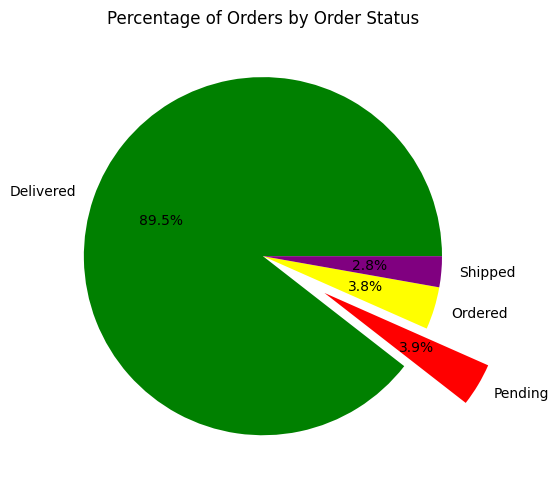

In [117]:
#chart 1
import matplotlib.pyplot as plt
status_counts = orders["Order_Status2"].value_counts()
plt.figure(figsize=(8, 5))
plt.pie(
    status_counts.values,
    labels=status_counts.index.astype(str),
    autopct="%1.1f%%",
    colors=["green", "red", "yellow", "purple"],
    explode=[0, 0.4, 0, 0])
plt.title("Percentage of Orders by Order Status")
plt.tight_layout()
plt.show()

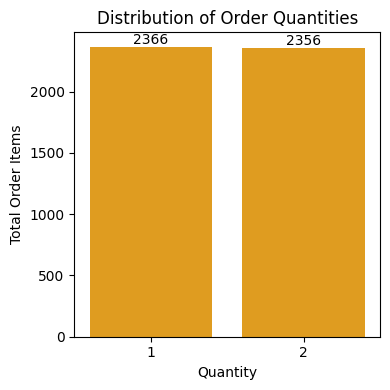

In [21]:
#CHART 2
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(4, 4))
hist=sns.countplot(data=order_items, x="Quantity", color="orange")
hist.bar_label(hist.containers[0])
plt.title("Distribution of Order Quantities")
plt.xlabel("Quantity")
plt.ylabel("Total Order Items")
plt.tight_layout()
plt.show()  

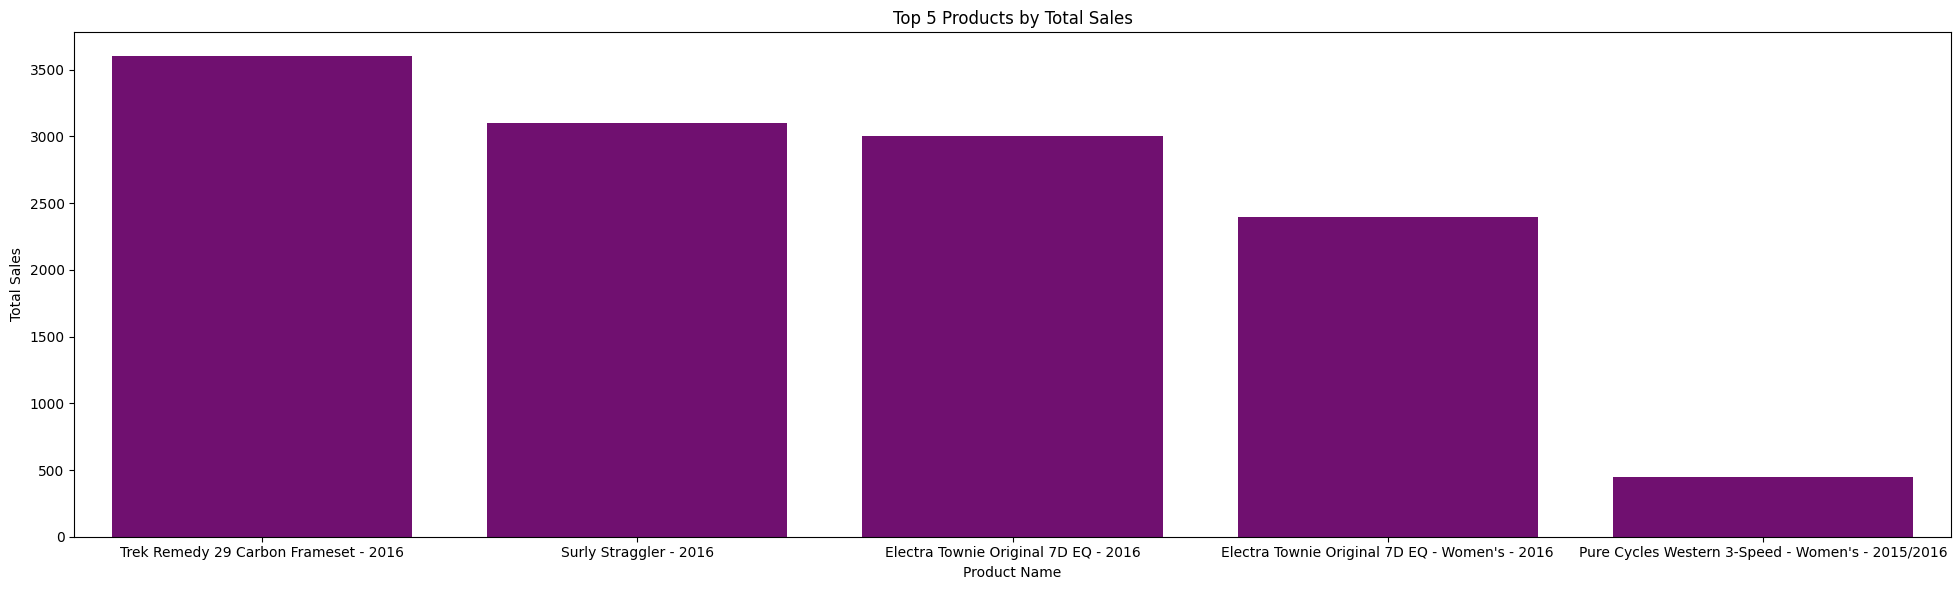

In [118]:
#Chart 3
import seaborn as sns
import matplotlib.pyplot as plt

df_clean = order_items.dropna(subset=["Product_Name"]).copy()

df_clean = df_clean[
    ~df_clean["Product_Name"].astype(str).str.strip().str.upper().isin(["NA", "N/A", "NULL", ""])]

# Calculate total sales by product
top_products = (df_clean.groupby("Product_Name")["Total_Sales"].sum() .reset_index().sort_values("Total_Sales", ascending=False).head(5))

# Plot bar chart
plt.figure(figsize=(20, 6))
sns.barplot(data=top_products, x="Product_Name", y="Total_Sales",color="purple")

plt.title("Top 5 Products by Total Sales")
plt.xlabel("Product Name")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

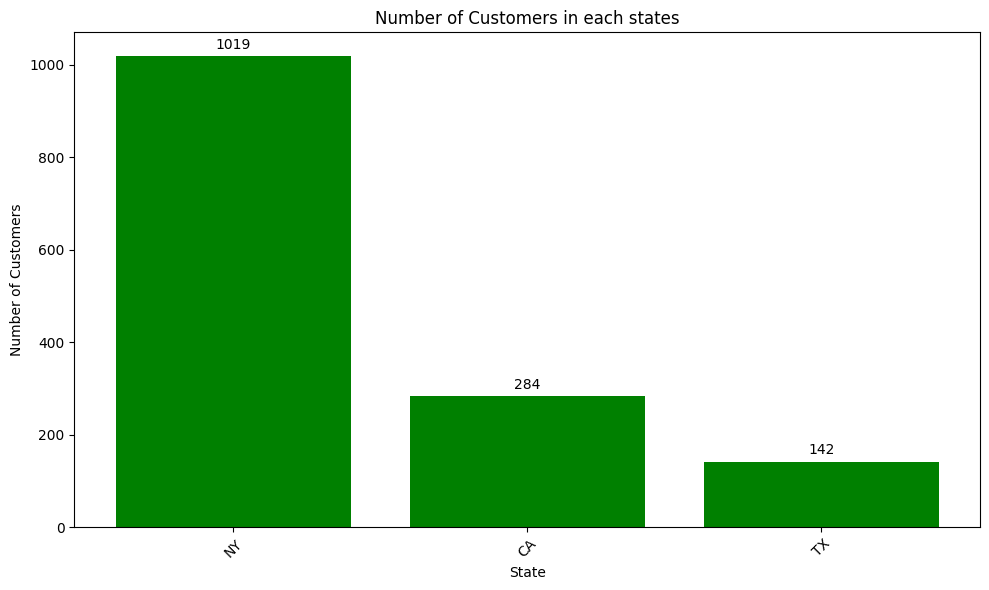

In [28]:
# Chart 4

import matplotlib.pyplot as plt

state_counts = customers["State"].value_counts()
plt.figure(figsize=(10, 6))
bars = plt.bar(state_counts.index, state_counts.values, color="green")
plt.bar_label(bars, padding=3)

plt.title("Number of Customers in each states")
plt.xlabel("State")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# TASK 3: 
# Calculate RFM Features for Customers 

In [8]:
print(orders["Order_date"].dtype)

str


In [9]:
# Step 1: Merge orders and order_items
merged = pd.merge(orders,order_items,
    left_on="order_id",
    right_on="Order_ID")
display(merged)

,order_id,Customer_id,Order_status,Order_Status2,Order_date,Required_date,Shipped_date,Store_id,Staff_id,Order_ID,Item_ID,Product_ID,Product_Name,Quantity,List_Price,Discount,Total_Sales
0,1,259,4,Delivered,2016-01-01,2016-01-03,2016-01-03,1,2,1,1,20,Electra Townie Original 7D EQ - Women's - 2016,1,599.99,0.20,599.79
1,1,259,4,Delivered,2016-01-01,2016-01-03,2016-01-03,1,2,1,2,8,Trek Remedy 29 Carbon Frameset - 2016,2,1799.99,0.07,3599.91
2,1,259,4,Delivered,2016-01-01,2016-01-03,2016-01-03,1,2,1,3,10,Surly Straggler - 2016,2,1549.00,0.05,3097.95
3,1,259,4,Delivered,2016-01-01,2016-01-03,2016-01-03,1,2,1,4,16,Electra Townie Original 7D EQ - 2016,2,599.99,0.05,1199.93
4,1,259,4,Delivered,2016-01-01,2016-01-03,2016-01-03,1,2,1,5,4,NA,1,2899.99,0.20,2899.79
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4717,1614,135,3,Shipped,2018-11-28,2018-11-28,NA,3,8,1614,2,159,NA,2,2299.99,0.07,4599.91
4718,1614,135,3,Shipped,2018-11-28,2018-11-28,NA,3,8,1614,3,213,NA,2,269.99,0.20,539.78
4719,1615,136,3,Shipped,2018-12-28,2018-12-28,NA,3,8,1615,1,197,NA,2,2299.99,0.20,4599.78
4720,1615,136,3,Shipped,2018-12-28,2018-12-28,NA,3,8,1615,2,214,NA,1,899.99,0.07,899.92


In [61]:
pd.set_option('display.max_rows', None)
display(merged.head(3))

,order_id,Customer_id,Order_status,Order_Status2,Order_date,Required_date,Shipped_date,Store_id,Staff_id,Order_ID,Item_ID,Product_ID,Product_Name,Quantity,List_Price,Discount,Total_Sales
0,1,259,4,Delivered,2016-01-01,2016-01-03,2016-01-03,1,2,1,1,20,Electra Townie Original 7D EQ - Women's - 2016,1,599.99,0.20,599.79
1,1,259,4,Delivered,2016-01-01,2016-01-03,2016-01-03,1,2,1,2,8,Trek Remedy 29 Carbon Frameset - 2016,2,1799.99,0.07,3599.91
2,1,259,4,Delivered,2016-01-01,2016-01-03,2016-01-03,1,2,1,3,10,Surly Straggler - 2016,2,1549.00,0.05,3097.95


In [12]:
# Step 2: Convert Order_date to datetime
merged["Order_date"] = pd.to_datetime( merged["Order_date"],format="%Y-%m-%d")

In [13]:
print(merged["Order_date"].dtype)

datetime64[us]


In [14]:
# Step 3: Calculate reference date
reference_date = merged["Order_date"].max() + pd.Timedelta(days=1)
print("Reference date:", reference_date)

Reference date: 2018-12-29 00:00:00


In [ ]:
rfm_data = merged.groupby("Customer_id").agg(
    Recency=("Order_date", lambda x: (reference_date - x.max()).days),
    Frequency=("order_id", "nunique"),
    Monetary=("Total_Sales", "sum")
).reset_index()

In [77]:
# STEP 4
import pandas as pd
import numpy as np

# 1. Calculate specific quantiles (percentiles)
recency_threshold = rfm_data["Recency"].quantile(0.50)      # Median (50th percentile)
frequency_threshold = rfm_data["Frequency"].quantile(0.70)  # 70th percentile
monetary_threshold = rfm_data["Monetary"].quantile(0.60)    # 60th percentile

# 2. Define the segmentation function using these quantiles
def segment_customer(row):
    if (row["Recency"] <= recency_threshold) and (
        row["Frequency"] >= frequency_threshold and row["Monetary"] >= monetary_threshold):
        return "Loyal"
    elif row["Recency"] > recency_threshold:
        return "At Risk"   
    else:
        return "Regular"

# 3. Apply it to your dataframe
rfm_data["Segment"] = rfm_data.apply(segment_customer, axis=1)

# 4. Check the breakdown and results
print(" Segment Breakdown /n")
print(rfm_data["Segment"].value_counts())

print("\n Segment Percentages ")
print((rfm_data["Segment"].value_counts(normalize=True) * 100).round(2))

print("\n First 10 Rows ")
print(rfm_data.head(10))

--- Segment Breakdown ---
Segment
At Risk    721
Regular    472
Loyal      252
Name: count, dtype: int64

--- Segment Percentages ---
Segment
At Risk    49.90
Regular    32.66
Loyal      17.44
Name: proportion, dtype: float64

--- First 10 Rows ---
   Customer_id  Recency  Frequency  Monetary  Segment
0            1       41         11  30644.78    Loyal
1            2      264         10  21652.87    Loyal
2            3       69         13  26248.66    Loyal
3            4      255          9  24197.81    Loyal
4            5      256          8  19442.01    Loyal
5            6      114         11  35856.83    Loyal
6            7      195          4   7707.64    Loyal
7            8      261          3   2603.58  Regular
8            9      246          9  26678.97    Loyal
9           10      128         11  37800.42    Loyal


# TASK 4
# To export to mysql

In [78]:
rfm_data.to_sql(
    name="customer_segments",
    con=engine,
    if_exists="replace",
    index=False
)

1445

In [79]:
# To check
check = pd.read_sql("SELECT * FROM customer_segments", engine)
display(check)

,Customer_id,Recency,Frequency,Monetary,Segment
0,1,41,11,30644.78,Loyal
1,2,264,10,21652.87,Loyal
2,3,69,13,26248.66,Loyal
3,4,255,9,24197.81,Loyal
4,5,256,8,19442.01,Loyal
...,...,...,...,...,...
1440,1441,337,3,10497.61,Regular
1441,1442,517,5,7841.32,Loyal
1442,1443,774,5,11237.59,At Risk
1443,1444,739,2,1749.57,At Risk
